In [22]:
import sys
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import scanpy as sc
import gseapy as gp
from metab_processing.metab_travlr_config import DATA_DIR
from metab_processing.SpaceTravLR.dataset_configs import dataset_paths
from metab_processing.LinearRegression.build_x import add_gene_signature
from metab_processing.LinearRegression.least_squares import (
    fit_gene_betas, subsample_gene_betas, rank_coefficients,
    plot_top_coefficients, plot_beta_histogram)

dataset = '13732_HS5_UC-Slice_4'
ANNOT_COL, CELL_TYPE = '25_06_11_ICI_5K_Coarse_annotations', 'IEC'
METHOD, PENALTY, STANDARDIZE = 'l1', 0.005, True
N_SUB = 50
LOWER, UPPER = 15, 85
DBVER = '2024.1.Hs'

SIGNATURES = [
    # Inflamation
    'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION',
    'HALLMARK_TNFA_SIGNALING_VIA_NFKB', 
    'HALLMARK_INFLAMMATORY_RESPONSE', 
    # Metabolic
    'HALLMARK_OXIDATIVE_PHOSPHORYLATION',
    'HALLMARK_GLYCOLYSIS',
    'HALLMARK_HYPOXIA',
    'HALLMARK_FATTY_ACID_METABOLISM',
    'HALLMARK_MTORC1_SIGNALING',
    # Negative control
    'HALLMARK_PANCREAS_BETA_CELLS',
]

In [11]:
adata = sc.read_h5ad(f'{DATA_DIR}/Alexi_UC_Spliced/{dataset}/LinearRegression/hvgall_x_adata.h5ad')
var = set(adata.var_names)
print(adata.n_obs, 'cells |', len(adata.uns['x_genes']), 'built genes')

3393 cells | 4736 built genes


In [ ]:
betas = fit_gene_betas(adata, genes=['CD3E'], annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                       method='l1', penalty=PENALTY, standardize=STANDARDIZE)
sub = subsample_gene_betas(adata, gene='CD3E', factors=None, n_subsamples=N_SUB,
                               annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                               method=METHOD, penalty=PENALTY, standardize=STANDARDIZE)
res = add_subsample_percentiles(rank_coefficients(betas), sub, LOWER, UPPER)

In [11]:
rank_coefficients(res).head(20)

,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
268,CD3E,IL7$IL2RG,lr,0.034787,0.200228,0.040091,0.071087,9364,0.007295,0.049237,0.024542,0.041772
628,CD3E,LCK$CD8A,lr,0.028511,0.167434,0.028034,0.071087,9364,0.010668,0.042524,0.019009,0.035370
272,CD3E,IL15$IL2RG,lr,0.016987,0.195284,0.038136,0.071087,9364,0.000000,0.036920,0.007848,0.026887
24,CD3E,HOXB7,tf,0.016503,0.147097,0.021637,0.071087,9364,0.004997,0.033546,0.012263,0.022551
864,CD3E,metab@Adenosine triphosphate,metab,0.014993,0.162500,0.026406,0.071087,9364,0.000000,0.025157,0.007178,0.018031
448,CD3E,LGALS9$CD44,lr,0.012189,0.153389,0.023528,0.071087,9364,0.000000,0.022372,0.005146,0.017983
574,CD3E,CD99$CD99,lr,0.011595,0.145604,0.021200,0.071087,9364,0.000000,0.023877,0.002465,0.016342
39,CD3E,STAT1,tf,0.006665,0.144343,0.020835,0.071087,9364,0.000000,0.027319,0.000355,0.013947
271,CD3E,IL15$IL2RB,lr,0.003865,0.132361,0.017519,0.071087,9364,0.000000,0.019753,0.000000,0.011269
368,CD3E,CD40LG$ITGB2,lr,0.002359,0.125578,0.015770,0.071087,9364,0.000000,0.013690,0.000000,0.007311


In [20]:
# Fetch the gene sets, print each, and report which genes are absent from the data.
msig = gp.Msigdb()
library = {}
for cat in ('h.all', 'c2.cp.kegg_legacy', 'c5.go.bp'):
    try:
        library.update(msig.get_gmt(category=cat, dbver=DBVER) or {})
    except Exception as e:
        print(f'{cat}: FAILED ({e})')

sets = {}        # name -> genes PRESENT in adata (what each pseudo-gene is built from)
for name in SIGNATURES:
    genes = library.get(name)
    if genes is None:
        print(f'MISSING SET (name not found in MSigDB): {name}')
        continue
    present = [g for g in genes if g in var]
    absent = [g for g in genes if g not in var]
    sets[name] = present
    print(f'{name}: {len(present)}/{len(genes)} genes present'
          + (f'  | missing: {absent}' if absent else ''))

GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION: 16/28 genes present  | missing: ['C1GALT1', 'CBFA2T2', 'FZD5', 'GATA5', 'MIR29B1', 'NKX3-2', 'NPY', 'SAV1', 'SPDEF', 'TIGAR', 'TMIGD1', 'YIPF6']
HALLMARK_TNFA_SIGNALING_VIA_NFKB: 109/200 genes present  | missing: ['AREG', 'B4GALT1', 'B4GALT5', 'BHLHE40', 'BIRC3', 'BTG1', 'BTG2', 'BTG3', 'CCL2', 'CCL4', 'CCL5', 'CCNL1', 'CD69', 'CEBPB', 'CEBPD', 'CLCF1', 'CXCL1', 'CXCL3', 'DENND5A', 'DUSP2', 'DUSP4', 'EFNA1', 'EGR1', 'EGR3', 'EHD1', 'EIF1', 'ETS2', 'F3', 'FJX1', 'FOS', 'FOSB', 'FOSL2', 'G0S2', 'GADD45B', 'GEM', 'GFPT2', 'GPR183', 'ID2', 'IER2', 'IER3', 'IER5', 'IFNGR2', 'IL7R', 'JUNB', 'KLF10', 'KLF2', 'KLF6', 'KLF9', 'KYNU', 'LITAF', 'MAFF', 'MAP2K3', 'MAP3K8', 'MARCKS', 'MCL1', 'NAMPT', 'NFIL3', 'NFKBIE', 'NR4A2', 'PDLIM5', 'PER1', 'PHLDA1', 'PLEK', 'PLK2', 'PLPP3', 'PMEPA1', 'PNRC1', 'PPP1R15A', 'PTPRE', 'RCAN1', 'RHOB', 'RIGI', 'RNF19B', 'SAT1', 'SERPINB8', 'SIK1', 'SLC16A6', 'SLC2A6', 'SNN', 'SOD2', 'SPSB1', 'TANK', 'TGIF1', 'TNFAIP2

In [26]:
for name in sets.keys():
    print(f'{name}: Present genes: {sets[name]}')

GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION: Present genes: ['CDKN1A', 'CDX2', 'GATA4', 'GATA6', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'PTK6', 'PYY', 'SOX9', 'SRC', 'TLR9', 'TYMS', 'YAP1']
HALLMARK_TNFA_SIGNALING_VIA_NFKB: Present genes: ['ABCA1', 'ACKR3', 'ATF3', 'ATP2B1', 'BCL2A1', 'BCL3', 'BCL6', 'BIRC2', 'BMP2', 'CCL20', 'CCN1', 'CCND1', 'CCRL2', 'CD44', 'CD80', 'CD83', 'CDKN1A', 'CFLAR', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'DNAJB4', 'DRAM1', 'DUSP1', 'DUSP5', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'FUT4', 'GADD45A', 'GCH1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IFIH1', 'IFIT2', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'IRS2', 'JAG1', 'JUN', 'KDM6B', 'KLF4', 'LAMB3', 'LDLR', 'LIF', 'MSC', 'MXD1', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NFKBIA', 'NINJ1', 'NR4A1', 'NR4A3', 'OLR1', 'PANX1', 'PDE4B', 'PFKFB3', 'PHLDA2', 'PLAU', 'PLAUR', 'PTGER4', 'PTGS2', 'PTX3', 'REL', 'RELA', 'RELB', 'RIPK2', 'SDC4', 'SERPINB2', '

In [6]:
sets['HALLMARK_INTERFERON_GAMMA_RESPONSE'] = [x for x in sets['HALLMARK_INTERFERON_GAMMA_RESPONSE'] if x not in {'STAT1', 'IRF1', 'STAT2', 'STAT3', 'STAT4', 'IRF4', 'IRF7', 'NFKB1', 'FAS', 'IL15'}]

In [7]:
print(sets['HALLMARK_INTERFERON_GAMMA_RESPONSE'])

['ADAR', 'APOL6', 'BANK1', 'CASP1', 'CASP3', 'CASP7', 'CASP8', 'CCL7', 'CD274', 'CD38', 'CD40', 'CD86', 'CDKN1A', 'CFB', 'CFH', 'CIITA', 'CMKLR1', 'CSF2RB', 'CXCL10', 'CXCL11', 'CXCL9', 'EIF2AK2', 'FCGR1A', 'FPR1', 'GCH1', 'GZMA', 'HIF1A', 'HLA-DRB1', 'ICAM1', 'IDO1', 'IFI35', 'IFI44L', 'IFIH1', 'IFIT1', 'IFIT2', 'IFIT3', 'IFITM2', 'IFNAR2', 'IL10RA', 'IL15RA', 'IL18BP', 'IL2RB', 'IL4R', 'IL6', 'IL7', 'IRF5', 'IRF8', 'JAK2', 'KLRK1', 'LATS2', 'MVP', 'MX1', 'MYD88', 'NCOA3', 'NFKBIA', 'NLRC5', 'NOD1', 'NUP93', 'OAS3', 'OGFR', 'PDE4B', 'PFKP', 'PIM1', 'PLA2G4A', 'PLSCR1', 'PML', 'PNP', 'PNPT1', 'PTGS2', 'PTPN1', 'PTPN6', 'RAPGEF6', 'RIPK1', 'RIPK2', 'RNF31', 'SAMHD1', 'SELP', 'SLAMF7', 'SOCS1', 'SOCS3', 'SP110', 'SRI', 'TAP1', 'TDRD7', 'TNFSF10', 'TRAFD1', 'TRIM21', 'TRIM25', 'VAMP5', 'VCAM1', 'ZBP1']


In [8]:
def add_subsample_percentiles(betas_df, sub, lower=LOWER, upper=UPPER):
    """Add min/max and lower/upper-percentile subsample-beta columns to betas_df,
    matched by factor (`sub` = n_subsamples x factor DataFrame from subsample_gene_betas)."""
    out = betas_df.copy()
    def stat(fn):
        return [fn(sub[f]) if f in sub.columns else np.nan for f in out['factor']]
    out['min_subsample_beta'] = stat(np.nanmin)
    out['max_subsample_beta'] = stat(np.nanmax)
    out[f'lower_{lower}_subsample_beta'] = stat(lambda s: np.nanpercentile(s, lower))
    out[f'upper_{upper}_subsample_beta'] = stat(lambda s: np.nanpercentile(s, upper))
    return out

In [9]:
def run_signature(name, penalty=PENALTY, n_sub=N_SUB, lower=LOWER, upper=UPPER, top=15):
    """All-positive pseudo-gene for `name` -> fit (L1/standardized) -> resample -> ranked
    betas with subsample-percentile columns. Prints a table + a top-coefficients plot.
    Returns (betas_with_percentiles, sub)."""
    if name not in sets:
        print(f'skip {name}: set not available'); return None, None
    genes = sets[name]
    ad2 = add_gene_signature(adata, name, positive=genes)   # negative=[] (all positive)
    b = fit_gene_betas(ad2, genes=[name], annot_col=ANNOT_COL, metabolites=[], annot_value=CELL_TYPE,
                       method=METHOD, penalty=penalty, standardize=STANDARDIZE)
    sub = subsample_gene_betas(ad2, name, factors=None, n_subsamples=n_sub,
                               annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                               method=METHOD, penalty=penalty, standardize=STANDARDIZE)
    res = add_subsample_percentiles(rank_coefficients(b), sub, lower, upper)
    print(f'=== {name}: {len(genes)} genes present ===')
    display(res.head(60))
    if not res.empty:
        plot_top_coefficients(b, top=top).set_title(name)
    return res, sub

## T cell biology

/global/home/users/fosterangus/.conda/envs/spacetravlr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.087594e+01, tolerance: 2.500e-01
  model = cd_fast.enet_coordinate_descent(
/global/home/users/fosterangus/.conda/envs/spacetravlr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.444768e+00, tolerance: 2.453e-01
  model = cd_fast.enet_coordinate_descent(
/global/home/users/fosterangus/.conda/envs/spacetravlr/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase 

=== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION: 16 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
1547,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CDX2,tf,0.422207,0.621059,3.857137e-01,0.983466,1949,0.327068,0.601688,0.390828,0.490473
42,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,KLF5,tf,0.359590,0.569306,3.241093e-01,0.983466,1949,0.277843,0.438882,0.325870,0.383694
1883,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,JAG1#HSF4,ltf,0.224907,0.039960,1.596782e-03,0.983466,1949,-0.015411,0.177148,0.000000,0.106207
1680,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,HIF1A,tf,0.219845,0.349987,1.224911e-01,0.983466,1949,0.085574,0.279077,0.139759,0.238580
630,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,ALCAM$CD6,lr,-0.212142,0.036775,1.352369e-03,0.983466,1949,-0.182314,0.000000,-0.061223,0.000000
729,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,DLL4$NOTCH4,lr,0.210377,0.004973,2.472629e-05,0.983466,1949,-0.035287,0.110457,-0.002326,0.007281
283,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CCL28$CCR3,lr,0.207800,0.064982,4.222615e-03,0.983466,1949,-0.071339,0.090464,0.000000,0.039116
631,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CD226$NECTIN2,lr,0.202804,0.044973,2.022526e-03,0.983466,1949,-0.064063,0.054850,-0.009422,0.024726
1136,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,GDNF#GATA4,ltf,-0.198602,0.117889,1.389784e-02,0.983466,1949,-0.112768,0.055791,-0.021622,0.001270
1566,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,PDGFC#HOXB5,ltf,-0.194826,0.025466,6.485227e-04,0.983466,1949,-0.181568,-0.000000,-0.133047,-0.016212


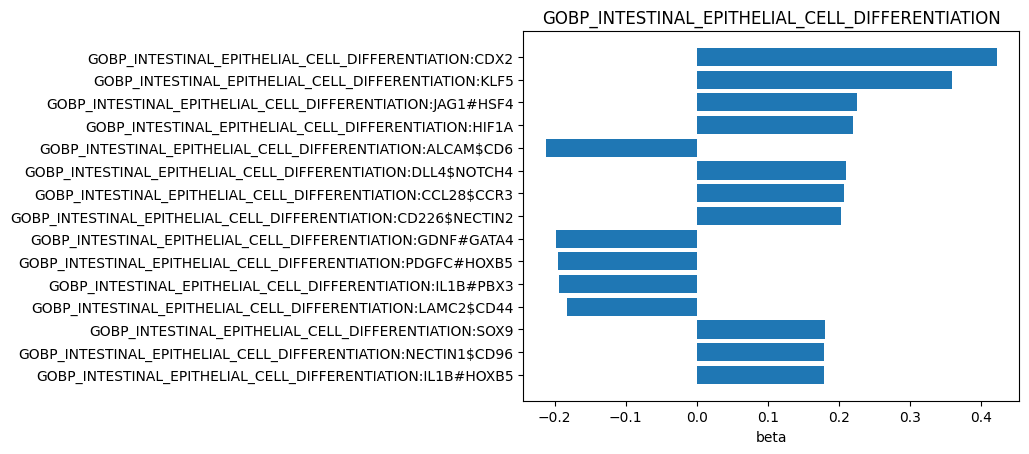

In [27]:
res_il2, sub_il2 = run_signature('GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION')

=== KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY: 80 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
694,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LCK$CD8A,lr,0.506890,0.327255,0.107096,0.697501,9364,0.426852,0.570833,0.479147,0.547349
391,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IL16$CD4,lr,0.282290,0.265047,0.070250,0.697501,9364,0.192128,0.312987,0.233110,0.295170
1618,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,NFATC3,tf,0.279963,0.221323,0.048984,0.697501,9364,0.216436,0.315110,0.246544,0.296245
1947,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,EWSR1,tf,0.258783,0.367003,0.134691,0.697501,9364,0.186975,0.310046,0.226825,0.272394
1617,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,NFATC2,tf,0.252386,0.178241,0.031770,0.697501,9364,0.162417,0.305645,0.221849,0.273874
2385,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ITGB2,tf,0.224502,0.342054,0.117001,0.697501,9364,0.153096,0.273945,0.189650,0.229548
79,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,RELA,tf,0.221065,0.219806,0.048315,0.697501,9364,0.171954,0.263891,0.190695,0.246510
1694,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IKZF1,tf,0.206232,0.277511,0.077012,0.697501,9364,0.146009,0.243709,0.169733,0.224432
1696,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IKZF3,tf,0.203741,0.227817,0.051901,0.697501,9364,0.168929,0.272169,0.183878,0.223112
334,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IL7$IL2RG,lr,0.202063,0.309838,0.096000,0.697501,9364,0.128417,0.249800,0.159969,0.216649


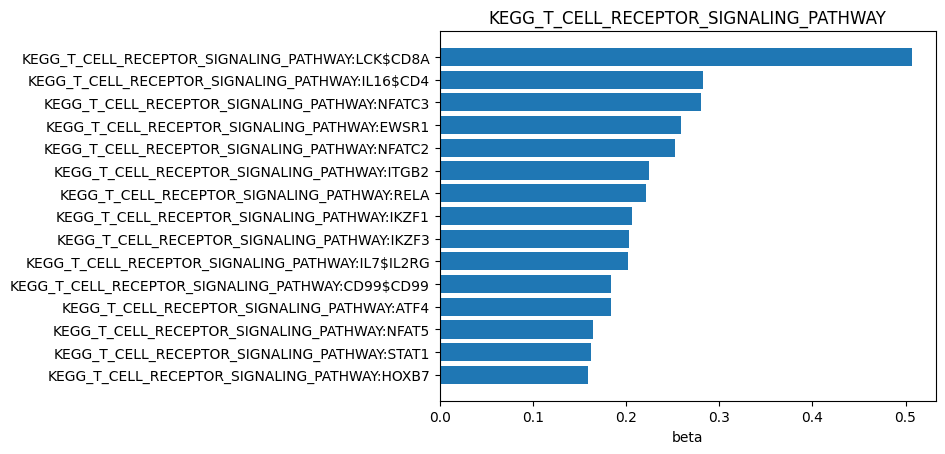

In [18]:
res_tcr, sub_tcr = run_signature('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')

=== GOBP_T_CELL_MEDIATED_CYTOTOXICITY: 36 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
2026,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ITGB2,tf,0.119662,0.307544,0.094583,0.473127,9364,0.079037,0.140141,0.096192,0.120393
889,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,STAT1,tf,0.106328,0.331892,0.110152,0.473127,9364,0.060674,0.114273,0.081213,0.105670
1732,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ATF4,tf,0.095236,0.305410,0.093275,0.473127,9364,0.045109,0.123923,0.073046,0.099133
330,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,IL16$CD4,lr,0.089881,0.246184,0.060607,0.473127,9364,0.041268,0.095427,0.056540,0.084775
579,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,CD99$CD99,lr,0.087673,0.295641,0.087404,0.473127,9364,0.043740,0.104036,0.065705,0.088355
1594,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,EWSR1,tf,0.073319,0.294853,0.086938,0.473127,9364,0.038480,0.111974,0.052729,0.086051
277,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,IL15$IL2RG,lr,0.062008,0.271218,0.073559,0.473127,9364,0.021096,0.093134,0.034259,0.066479
683,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,SEMA4D$PLXNB2,lr,0.058457,0.211020,0.044529,0.473127,9364,0.017860,0.094526,0.033491,0.077054
861,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,HOXB7,tf,0.053818,0.266462,0.071002,0.473127,9364,0.000000,0.089350,0.038964,0.068636
2160,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,CBX5,tf,0.052129,0.225840,0.051004,0.473127,9364,0.007749,0.069910,0.029577,0.056578


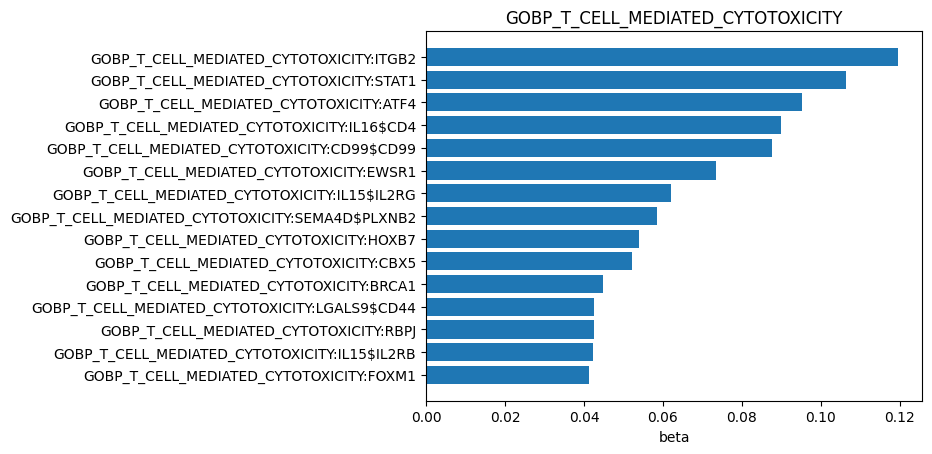

In [19]:
res_tcyto, sub_tcyto = run_signature('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')

=== KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY: 88 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
2233,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,ITGB2,tf,0.661454,0.455060,0.207080,0.711958,9364,0.594289,0.704616,0.621147,0.670978
1875,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,NFATC3,tf,0.285251,0.230807,0.053272,0.711958,9364,0.238104,0.324871,0.258811,0.307217
695,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,LCK$CD8A,lr,0.266826,0.278975,0.077827,0.711958,9364,0.203213,0.358912,0.243737,0.301817
2400,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,EWSR1,tf,0.238085,0.369223,0.136325,0.711958,9364,0.186788,0.300341,0.215266,0.262639
1874,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,NFATC2,tf,0.201893,0.164803,0.027160,0.711958,9364,0.159835,0.245319,0.177397,0.224266
2296,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,NFAT5,tf,0.192813,0.162174,0.026300,0.711958,9364,0.123761,0.239371,0.148910,0.217325
662,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,ICAM1$ITGAL,lr,0.188977,0.278579,0.077606,0.711958,9364,0.146848,0.223026,0.167426,0.206492
2123,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,IKZF1,tf,0.188291,0.281129,0.079034,0.711958,9364,0.125270,0.237242,0.157162,0.212524
420,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,FASLG$FAS,lr,0.167863,0.196753,0.038712,0.711958,9364,0.128222,0.225318,0.146713,0.198612
2125,KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY,IKZF3,tf,0.158359,0.215639,0.046500,0.711958,9364,0.114461,0.201932,0.137774,0.183365


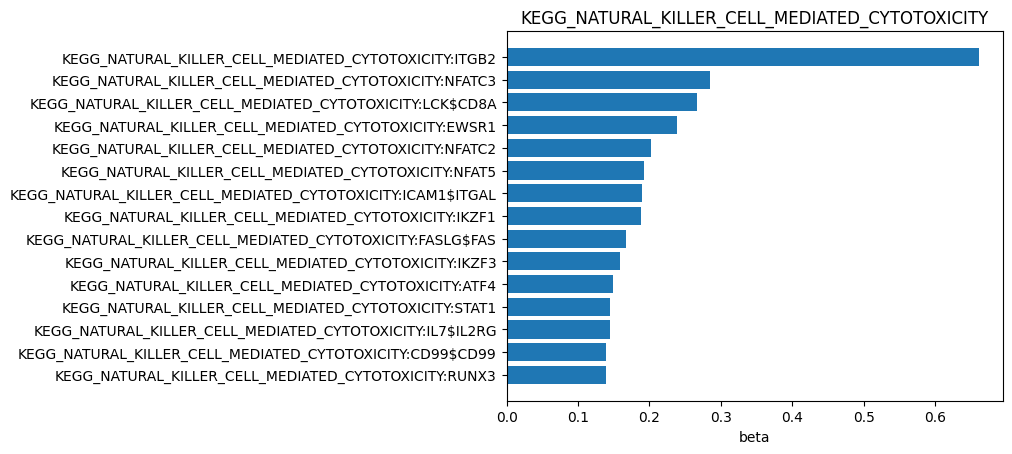

In [20]:
res_nk, sub_nk = run_signature('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')

=== HALLMARK_TNFA_SIGNALING_VIA_NFKB: 109 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
42,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IRF1,tf,0.541737,0.394635,0.155736,0.778264,9364,0.454070,0.554636,0.497130,0.546542
514,HALLMARK_TNFA_SIGNALING_VIA_NFKB,LGALS9$CD44,lr,0.388063,0.420907,0.177162,0.778264,9364,0.304501,0.394685,0.321502,0.364009
2186,HALLMARK_TNFA_SIGNALING_VIA_NFKB,NFE2L2,tf,0.330967,0.338177,0.114364,0.778264,9364,0.255420,0.347890,0.285210,0.326417
426,HALLMARK_TNFA_SIGNALING_VIA_NFKB,TNFSF9$TNFRSF9,lr,0.263091,0.253048,0.064033,0.778264,9364,0.170549,0.330241,0.216162,0.277429
672,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ITGB2$ICAM1,lr,0.252639,0.299299,0.089580,0.778264,9364,0.164295,0.280728,0.202782,0.257183
1120,HALLMARK_TNFA_SIGNALING_VIA_NFKB,RELA,tf,0.238241,0.256042,0.065558,0.778264,9364,0.182034,0.275107,0.214844,0.255996
61,HALLMARK_TNFA_SIGNALING_VIA_NFKB,NFKB2,tf,0.216890,0.225392,0.050801,0.778264,9364,0.149599,0.243593,0.185358,0.221330
410,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IFNG$IFNGR2,lr,0.192859,0.250472,0.062736,0.778264,9364,0.104781,0.260984,0.150860,0.225793
94,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT1,tf,0.191336,0.386292,0.149222,0.778264,9364,0.108093,0.184771,0.128954,0.164169
1649,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT5A,tf,0.176253,0.187973,0.035334,0.778264,9364,0.125131,0.230587,0.158142,0.191432


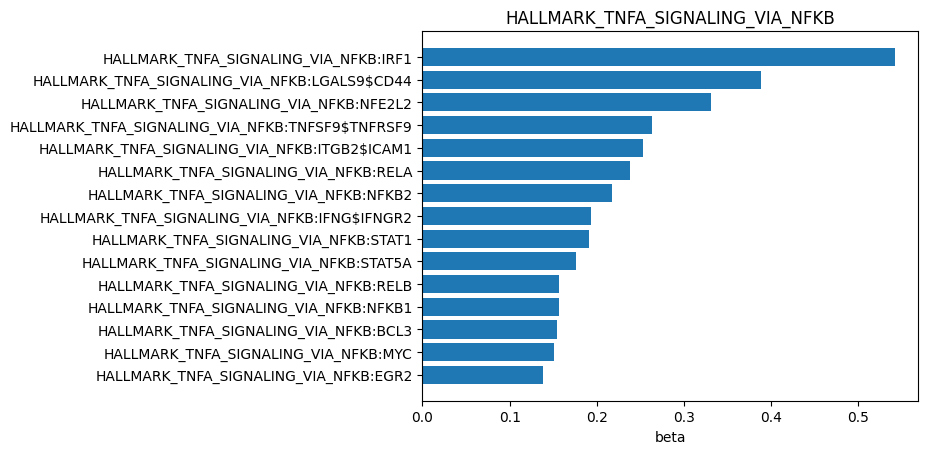

In [21]:
res_tnfa, sub_tnfa = run_signature('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

In [23]:
res_ifng, sub_ifng = run_signature('HALLMARK_INTERFERON_GAMMA_RESPONSE')   # positive control

skip HALLMARK_INTERFERON_GAMMA_RESPONSE: set not available


## Metabolic

In [24]:
res_oxphos, sub_oxphos = run_signature('HALLMARK_OXIDATIVE_PHOSPHORYLATION')

=== HALLMARK_OXIDATIVE_PHOSPHORYLATION: 44 genes present ===


/global/home/users/fosterangus/Projects/MetabTravLR/SpaceTravLR/metab_processing/LinearRegression/least_squares.py:361: UserWarning: fit_gene_betas: 'HALLMARK_OXIDATIVE_PHOSPHORYLATION' has too few cells (1949 < 2348); skipping.
  warnings.warn(f"fit_gene_betas: {gene!r} has too few cells "


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta


In [25]:
res_glyc, sub_glyc = run_signature('HALLMARK_GLYCOLYSIS')

=== HALLMARK_GLYCOLYSIS: 70 genes present ===


/global/home/users/fosterangus/Projects/MetabTravLR/SpaceTravLR/metab_processing/LinearRegression/least_squares.py:361: UserWarning: fit_gene_betas: 'HALLMARK_GLYCOLYSIS' has too few cells (1949 < 2386); skipping.
  warnings.warn(f"fit_gene_betas: {gene!r} has too few cells "


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta


=== HALLMARK_HYPOXIA: 96 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
838,HALLMARK_HYPOXIA,ETS1,tf,0.322687,0.276334,0.076360,0.678983,9364,0.279272,0.357905,0.304561,0.338294
1226,HALLMARK_HYPOXIA,RBPJ,tf,0.249848,0.282276,0.079680,0.678983,9364,0.198105,0.282844,0.211273,0.263939
575,HALLMARK_HYPOXIA,CD99$CD99,lr,0.186658,0.349952,0.122466,0.678983,9364,0.128296,0.204461,0.144237,0.190580
832,HALLMARK_HYPOXIA,ATF4,tf,0.183296,0.353114,0.124690,0.678983,9364,0.107794,0.208760,0.149765,0.186745
851,HALLMARK_HYPOXIA,NR3C1,tf,0.158309,0.161146,0.025968,0.678983,9364,0.117506,0.218431,0.129010,0.161861
1438,HALLMARK_HYPOXIA,EWSR1,tf,0.155710,0.337736,0.114066,0.678983,9364,0.106960,0.207103,0.130448,0.175268
262,HALLMARK_HYPOXIA,CXCL12$CXCR4,lr,0.136500,0.135710,0.018417,0.678983,9364,0.100366,0.179493,0.117106,0.158378
1962,HALLMARK_HYPOXIA,ITGB2,tf,0.132040,0.298533,0.089122,0.678983,9364,0.049687,0.133081,0.075741,0.122099
1212,HALLMARK_HYPOXIA,FOXO3,tf,0.131735,0.144303,0.020823,0.678983,9364,0.092169,0.167841,0.116575,0.148170
2031,HALLMARK_HYPOXIA,HOXB7,tf,0.129511,0.306566,0.093983,0.678983,9364,0.092775,0.183924,0.116528,0.156428


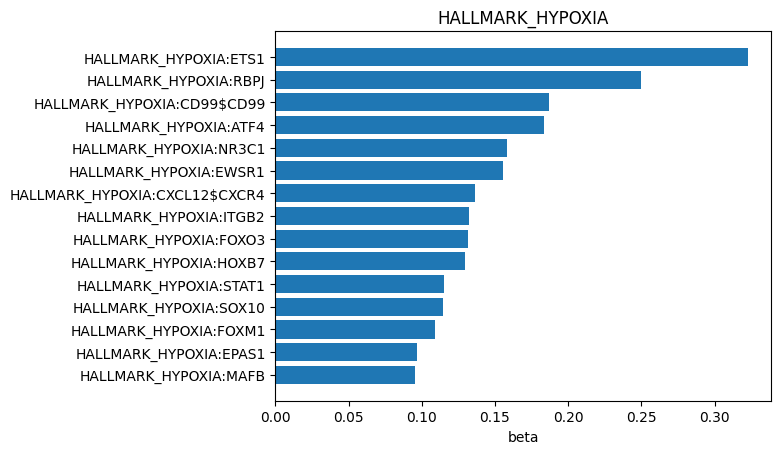

In [10]:
res_hyp, sub_hyp = run_signature('HALLMARK_HYPOXIA')

=== HALLMARK_FATTY_ACID_METABOLISM: 47 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
1836,HALLMARK_FATTY_ACID_METABOLISM,SOX10,tf,0.137307,0.328220,0.107729,0.543261,9364,0.085666,0.162071,0.096891,0.135946
2240,HALLMARK_FATTY_ACID_METABOLISM,ATF4,tf,0.117781,0.336422,0.113180,0.543261,9364,0.065698,0.139975,0.089192,0.120309
101,HALLMARK_FATTY_ACID_METABOLISM,TFAP2A,tf,0.110213,0.307337,0.094456,0.543261,9364,0.069151,0.128281,0.088336,0.118748
1115,HALLMARK_FATTY_ACID_METABOLISM,MYBL2,tf,0.106556,0.267057,0.071319,0.543261,9364,0.056515,0.132781,0.080443,0.119018
2008,HALLMARK_FATTY_ACID_METABOLISM,HMGA1,tf,0.105177,0.324397,0.105233,0.543261,9364,0.037933,0.119228,0.072156,0.106877
640,HALLMARK_FATTY_ACID_METABOLISM,CD99$CD99,lr,0.100067,0.325345,0.105849,0.543261,9364,0.061962,0.116164,0.073421,0.097012
95,HALLMARK_FATTY_ACID_METABOLISM,STAT1,tf,0.092296,0.326923,0.106879,0.543261,9364,0.053213,0.116136,0.065706,0.095105
2184,HALLMARK_FATTY_ACID_METABOLISM,EWSR1,tf,0.074580,0.291901,0.085206,0.543261,9364,0.032379,0.101394,0.061154,0.082979
1211,HALLMARK_FATTY_ACID_METABOLISM,HOXB7,tf,0.072073,0.298237,0.088945,0.543261,9364,0.057742,0.101474,0.067635,0.092513
1515,HALLMARK_FATTY_ACID_METABOLISM,TRIM28,tf,0.071693,0.240331,0.057759,0.543261,9364,0.033933,0.113935,0.044963,0.080239


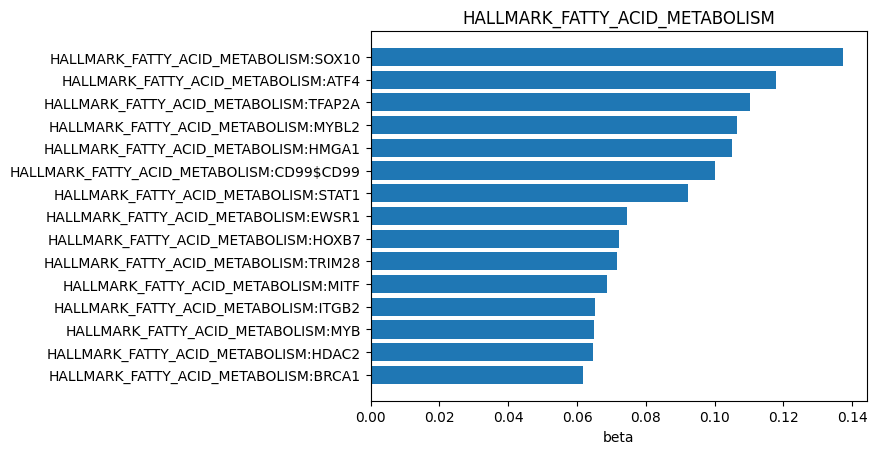

In [11]:
res_fao, sub_fao = run_signature('HALLMARK_FATTY_ACID_METABOLISM')

=== HALLMARK_MTORC1_SIGNALING: 91 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
2373,HALLMARK_MTORC1_SIGNALING,ITGB2,tf,0.687642,0.387232,0.149948,0.777188,9364,0.562591,0.679985,0.600289,0.668109
59,HALLMARK_MTORC1_SIGNALING,MYBL2,tf,0.436919,0.350010,0.122507,0.777188,9364,0.300792,0.519815,0.354231,0.449012
1460,HALLMARK_MTORC1_SIGNALING,XBP1,tf,0.344786,0.190396,0.036251,0.777188,9364,0.281356,0.387707,0.298726,0.350506
1832,HALLMARK_MTORC1_SIGNALING,HMGA1,tf,0.310030,0.375027,0.140646,0.777188,9364,0.185977,0.328378,0.228914,0.293062
2043,HALLMARK_MTORC1_SIGNALING,FOXM1,tf,0.294370,0.329000,0.108241,0.777188,9364,0.202842,0.367993,0.245391,0.320421
1323,HALLMARK_MTORC1_SIGNALING,HOXB7,tf,0.262521,0.330940,0.109521,0.777188,9364,0.132331,0.327611,0.211455,0.298059
1607,HALLMARK_MTORC1_SIGNALING,ATF4,tf,0.260628,0.381740,0.145726,0.777188,9364,0.155425,0.288034,0.205185,0.260842
656,HALLMARK_MTORC1_SIGNALING,CD99$CD99,lr,0.257545,0.364399,0.132787,0.777188,9364,0.147647,0.311011,0.191293,0.243480
2009,HALLMARK_MTORC1_SIGNALING,EWSR1,tf,0.238089,0.364037,0.132523,0.777188,9364,0.174078,0.275018,0.204561,0.243525
116,HALLMARK_MTORC1_SIGNALING,TRIM28,tf,0.225467,0.284776,0.081097,0.777188,9364,0.123485,0.270355,0.159536,0.243241


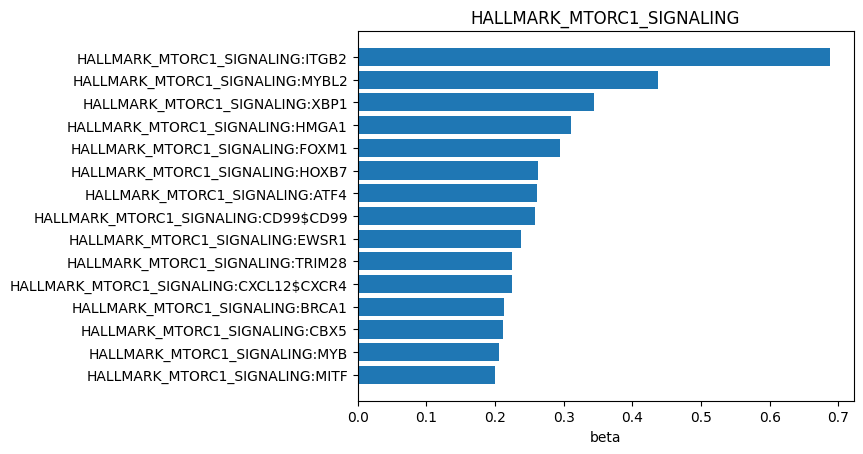

In [12]:
res_mtor, sub_mtor = run_signature('HALLMARK_MTORC1_SIGNALING')

## Negative control

=== HALLMARK_PANCREAS_BETA_CELLS: 18 genes present ===


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta
1088,HALLMARK_PANCREAS_BETA_CELLS,MAFB,tf,0.120067,0.480558,2.309355e-01,0.433086,9364,0.107340,0.136217,0.115871,0.125801
2107,HALLMARK_PANCREAS_BETA_CELLS,FOXO1,tf,0.075560,0.353199,1.247499e-01,0.433086,9364,0.065506,0.083982,0.070835,0.081401
1324,HALLMARK_PANCREAS_BETA_CELLS,VDR,tf,0.073581,0.360498,1.299587e-01,0.433086,9364,0.060049,0.085040,0.067580,0.079726
1976,HALLMARK_PANCREAS_BETA_CELLS,LMO2,tf,0.017690,0.205470,4.221792e-02,0.433086,9364,0.009455,0.029385,0.013399,0.022690
1443,HALLMARK_PANCREAS_BETA_CELLS,FGF4#PDX1,ltf,0.000000,0.000000,0.000000e+00,0.433086,9364,0.000000,0.000000,0.000000,0.000000
1445,HALLMARK_PANCREAS_BETA_CELLS,TGFB1#PPARA,ltf,0.000000,-0.000415,1.718951e-07,0.433086,9364,-0.000000,-0.000000,0.000000,0.000000
1446,HALLMARK_PANCREAS_BETA_CELLS,MSTN#PPARA,ltf,0.000000,0.008390,7.039559e-05,0.433086,9364,0.000000,0.000000,0.000000,0.000000
1447,HALLMARK_PANCREAS_BETA_CELLS,TNF#PPARA,ltf,-0.000000,0.001127,1.269154e-06,0.433086,9364,-0.000000,-0.000000,0.000000,0.000000
1448,HALLMARK_PANCREAS_BETA_CELLS,EGF#PPARA,ltf,0.000000,-0.000570,3.250682e-07,0.433086,9364,0.000000,0.000000,0.000000,0.000000
1449,HALLMARK_PANCREAS_BETA_CELLS,TNF#PPARD,ltf,0.000000,0.024354,5.931147e-04,0.433086,9364,0.000000,0.000000,0.000000,0.000000


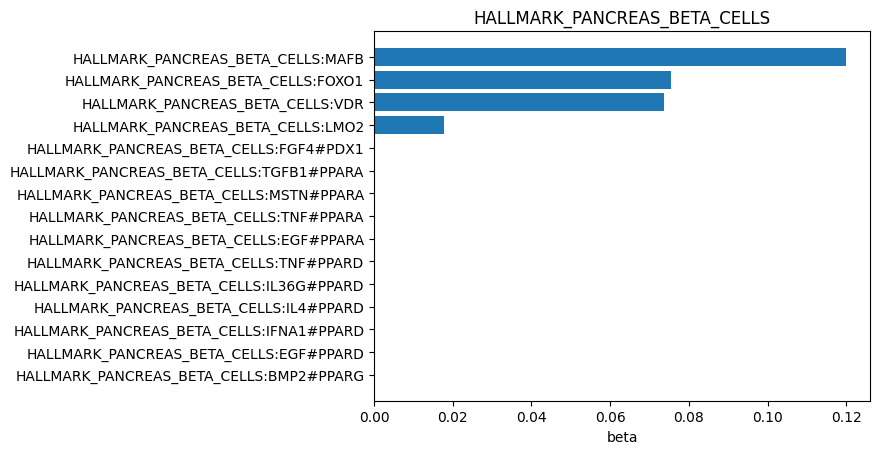

In [13]:
res_neg, sub_neg = run_signature('HALLMARK_PANCREAS_BETA_CELLS')

## Distribution of a single factor (edit the signature / factor)

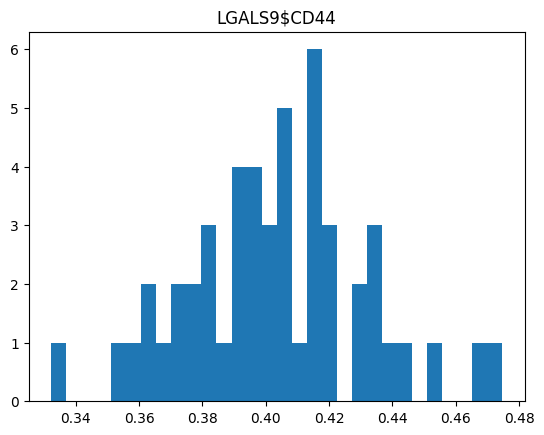

In [12]:
sub = sub_il2                 # <- any signature's resample output from above
FACTOR = 'LGALS9$CD44' # <- any factor name (tf / lig$rec / lig#tf / metab@name)
plot_beta_histogram(sub[FACTOR], title=FACTOR);

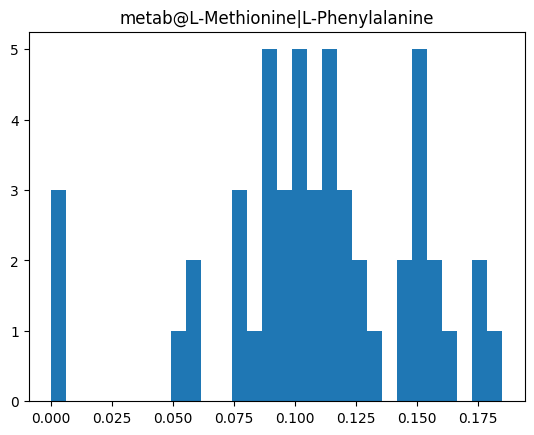

In [13]:
sub = sub_il2                 # <- any signature's resample output from above
FACTOR = 'metab@L-Methionine|L-Phenylalanine' # <- any factor name (tf / lig$rec / lig#tf / metab@name)
plot_beta_histogram(sub[FACTOR], title=FACTOR);

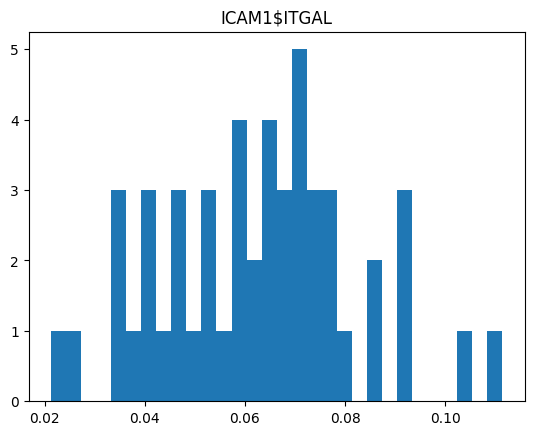

In [14]:
sub = sub_il2                 # <- any signature's resample output from above
FACTOR = 'ICAM1$ITGAL' # <- any factor name (tf / lig$rec / lig#tf / metab@name)
plot_beta_histogram(sub[FACTOR], title=FACTOR);